# G30: Metadata-Filtered RAG for Image Captioning
## Phase 1: data preparation, cleaning, exploration and knowledge base

**How to use this notebook**
- Run the cells **from top to bottom, one at a time** (click the play button, wait for the result).
- **Teammates:** run **Part A only** (restore and verify). Use the *Light* zip.
- **Leader:** run Part A with the *full* zip, then Part B (cleaning, test detections, charts), then Part C (packaging).
- Never press "Run all" without reading the cells first.
- Settings you may change are all in the **CONFIG** cell below. Nothing else needs editing.

**Which cells does each person run?**

| Who | Cells | What for |
|---|---|---|
| **Teammates** | **Part A only** (A1 to A4) | Restore the files and prove they are correct |
| **Leader** | Part A, then **Part B**, then **Part C** | Also create the cleaning report, test detections, charts, and the files for GitHub |

**Two zips on Drive**
- **Full zip** (`RAG_Project_Phase1_Fixed_Submission.zip`, over 2 GB): contains the 11,000 photos and the COCO annotation files. Only the leader needs it, for Part B.
- **Light zip** (`RAG_Project_Phase1_Light.zip`, created by cell C1): no photos, so it is much smaller. It is what you share with teammates.

In [1]:
# ===== CONFIG (edit only here) =====
SEED = 42
ZIP_NAME = "RAG_Project_Phase1_Fixed_Submission.zip"   # leader: full zip (has photos). Teammates: "RAG_Project_Phase1_Light.zip"
EXPECTED_TEST = 1000      # change to 100 if the professor confirms
YOLO_CONF = 0.25          # same detector threshold for library, validation and test photos
DRIVE_OUT = "/content/drive/MyDrive/g30_project/phase1_outputs"

---
# Part A: Restore and verify
**Why:** brings back the frozen splits, YOLO metadata, embeddings and FAISS indexes from the zip on Google Drive, then proves they are correct.

### A1. Mount Drive and restore the project files
The zip must be in your **My Drive** (top level). If it is only under *Shared with me*: right-click it, then **Make a copy**.

In [2]:
# ===== A1: Mount Drive and restore project files =====
import os, shutil, zipfile
from google.colab import drive
drive.mount('/content/drive')

candidates = [f"/content/drive/MyDrive/{ZIP_NAME}", f"/content/drive/My Drive/{ZIP_NAME}"]
zip_path = next((p for p in candidates if os.path.exists(p)), None)

if zip_path is None:
    raise FileNotFoundError(f"{ZIP_NAME} not found in your My Drive. "
                            "Right-click the shared file -> Make a copy, then re-run.")
if not zipfile.is_zipfile(zip_path):
    raise ValueError("The file is not a valid ZIP (incomplete copy?). Copy it again.")

shutil.copy(zip_path, "/content/_phase1.zip")      # copy first: more reliable than reading from Drive
shutil.unpack_archive("/content/_phase1.zip", extract_dir="/content")
os.remove("/content/_phase1.zip")
print("✅ Restored. Folders in /content/data:", sorted(os.listdir("/content/data")))

Mounted at /content/drive
✅ Restored. Folders in /content/data: ['coco', 'embeddings', 'index', 'processed', 'splits']


### A2. Install the libraries (one cell only)

In [3]:
# ===== A2: Install libraries =====
!pip install -q faiss-cpu==1.15.1 ultralytics==8.4.197 matplotlib seaborn tqdm imagehash nltk
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: False


### A3. Show what was restored (photos are hidden)

In [4]:
# ===== A3: File tree =====
!find /content/data /content/reports -maxdepth 2 -not -name "*.jpg" 2>/dev/null | sort | head -60
!ls -lh /content/data/splits /content/data/processed /content/data/embeddings /content/data/index

/content/data
/content/data/coco
/content/data/coco/annotations
/content/data/coco/train2017
/content/data/coco/val2017
/content/data/embeddings
/content/data/embeddings/embedding_manifest.json
/content/data/embeddings/kb_caption_embeddings.npy
/content/data/embeddings/kb_caption_ids.npy
/content/data/embeddings/kb_image_embeddings.npy
/content/data/embeddings/kb_image_ids.npy
/content/data/embeddings/test_image_embeddings.npy
/content/data/embeddings/test_image_ids.npy
/content/data/embeddings/val_image_embeddings.npy
/content/data/embeddings/val_image_ids.npy
/content/data/index
/content/data/index/caption_to_image.json
/content/data/index/kb_caption.index
/content/data/index/kb_image.index
/content/data/index/kb_manifest.json
/content/data/index/kb_records.json
/content/data/processed
/content/data/processed/caption_audit.json
/content/data/processed/eval_references_test.json
/content/data/processed/eval_references_val.json
/content/data/processed/kb_captions.jsonl
/content/data/pro

### A4. Audit: integrity checks
Stops at missing files. Never says "passed" if something was skipped. **Pass criteria: the last line says `ALL CHECKS PASSED`.**

In [5]:
# ===== A4: Audit, Phase 1 integrity checks =====
import json, os, numpy as np, faiss
errors = []
def check(ok, msg):
    print(("   ✅ " if ok else "   ❌ ") + msg)
    if not ok:
        errors.append(msg)

files = ["data/splits/kb_ids.json", "data/splits/val_ids.json", "data/splits/test_ids.json",
         "data/processed/yolo_metadata.json",
         "data/embeddings/kb_image_embeddings.npy", "data/embeddings/kb_caption_embeddings.npy",
         "data/index/kb_image.index", "data/index/kb_caption.index",
         "data/index/caption_to_image.json", "data/index/kb_records.json", "data/index/kb_manifest.json"]
for p in files:
    check(os.path.exists(p) and os.path.getsize(p) > 0, f"present and non-empty: {p}")
if errors:
    raise RuntimeError("Missing files, stopping: " + "; ".join(errors))

load = lambda p: json.load(open(p))
kb, val, test = (load(f"data/splits/{n}_ids.json") for n in ("kb", "val", "test"))
check(len(kb) == len(set(kb)) == 10000, "KB: 10,000 unique IDs")
check(len(val) == 100, "Validation: 100 IDs")
check(len(test) == EXPECTED_TEST, f"Test: {EXPECTED_TEST} IDs")
check(not (set(kb) & set(val)) and not (set(kb) & set(test)) and not (set(val) & set(test)),
      "no overlap between any two splits")

yolo = load("data/processed/yolo_metadata.json")
check(set(map(int, yolo)) >= set(kb) | set(val), "YOLO metadata covers all KB and validation photos")
print(f"   ℹ️  photos with no detected object: {sum(1 for m in yolo.values() if not m['objects'])}/{len(yolo)}")

kb_img = np.load("data/embeddings/kb_image_embeddings.npy")
kb_cap = np.load("data/embeddings/kb_caption_embeddings.npy")
check(kb_img.shape == (len(kb), 512) and kb_img.dtype == np.float32, f"image embeddings {kb_img.shape} {kb_img.dtype}")
check(kb_cap.ndim == 2 and kb_cap.shape[1] == 512, f"caption embeddings {kb_cap.shape}")
check(not np.isnan(kb_img).any() and not np.isnan(kb_cap).any(), "no NaN values")
for name, ids in (("val", val), ("test", test)):
    ep = f"data/embeddings/{name}_image_embeddings.npy"
    if os.path.exists(ep):
        e = np.load(ep)
        check(e.shape == (len(ids), 512), f"{name} image embeddings {e.shape}")
    else:
        print(f"   ℹ️  {ep} not found (not required for this audit)")
check(np.allclose(np.linalg.norm(kb_img, axis=1), 1, atol=1e-3), "image vectors are L2-normalised")

ii = faiss.read_index("data/index/kb_image.index")
ci = faiss.read_index("data/index/kb_caption.index")
check(ii.ntotal == len(kb_img), f"image index holds {ii.ntotal} vectors")
check(ci.ntotal == len(kb_cap), f"caption index holds {ci.ntotal} vectors")
check(len(load("data/index/caption_to_image.json")) == ci.ntotal, "caption_to_image.json: one entry per caption vector")

if errors:
    raise AssertionError(f"{len(errors)} check(s) failed: {errors}")
print("\n🎉 ALL CHECKS PASSED")

   ✅ present and non-empty: data/splits/kb_ids.json
   ✅ present and non-empty: data/splits/val_ids.json
   ✅ present and non-empty: data/splits/test_ids.json
   ✅ present and non-empty: data/processed/yolo_metadata.json
   ✅ present and non-empty: data/embeddings/kb_image_embeddings.npy
   ✅ present and non-empty: data/embeddings/kb_caption_embeddings.npy
   ✅ present and non-empty: data/index/kb_image.index
   ✅ present and non-empty: data/index/kb_caption.index
   ✅ present and non-empty: data/index/caption_to_image.json
   ✅ present and non-empty: data/index/kb_records.json
   ✅ present and non-empty: data/index/kb_manifest.json
   ✅ KB: 10,000 unique IDs
   ✅ Validation: 100 IDs
   ✅ Test: 1000 IDs
   ✅ no overlap between any two splits
   ✅ YOLO metadata covers all KB and validation photos
   ℹ️  photos with no detected object: 182/10100
   ✅ image embeddings (10000, 512) float32
   ✅ caption embeddings (50031, 512)
   ✅ no NaN values
   ✅ val image embeddings (100, 512)
   ✅ tes

---
# Part B: Cleaning, test-photo detections and exploration (leader only)
Needs the **full zip** (photos). Teammates skip to the end.
### B0. Check that photos and annotation files are present

In [6]:
# ===== B0: Photos and annotations present? =====
import os, urllib.request, zipfile
HAVE_PHOTOS = (os.path.isdir("data/coco/train2017") and len(os.listdir("data/coco/train2017")) >= 10100
               and os.path.isdir("data/coco/val2017") and len(os.listdir("data/coco/val2017")) >= EXPECTED_TEST)
print("photos available:", HAVE_PHOTOS)
if not HAVE_PHOTOS:
    print("⚠️ Part B needs the full zip with photos. Skip Part B, or set ZIP_NAME to the full zip and re-run A1.")

ANN = "data/coco/annotations"
need = ["captions_train2017.json", "captions_val2017.json", "instances_train2017.json"]
if HAVE_PHOTOS and not all(os.path.exists(f"{ANN}/{n}") for n in need):
    print("📥 Downloading COCO annotations (about 1 minute)...")
    os.makedirs("data/coco", exist_ok=True)
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", "ann.zip")
    with zipfile.ZipFile("ann.zip") as z:
        z.extractall("data/coco")
    os.remove("ann.zip")
if HAVE_PHOTOS:
    print("annotation files:", all(os.path.exists(f"{ANN}/{n}") for n in need))

photos available: True
annotation files: True


### B1. Cleaning report (report only, nothing is removed)
Checks missing, corrupted and duplicate photos, and the number of captions per photo. Removing a photo would change the frozen IDs and break the embeddings, so we read the numbers first.

In [7]:
# ===== B1: Cleaning audit =====
import json, hashlib, collections
from pathlib import Path
from PIL import Image, ImageOps
import imagehash
from tqdm import tqdm
assert HAVE_PHOTOS, "Run B0 first and use the full zip."

splits = {n: json.load(open(f"data/splits/{n}_ids.json")) for n in ("kb", "val", "test")}
folder = {"kb": "data/coco/train2017", "val": "data/coco/train2017", "test": "data/coco/val2017"}
report = {"missing": [], "corrupted": [], "exact_duplicates": [], "near_duplicates": [],
          "cross_split_duplicates": [], "fewer_than_5_captions": [], "more_than_5_captions": []}
seen_md5, seen_ph = {}, {}

for split, ids in splits.items():
    for iid in tqdm(ids, desc=f"checking {split}"):
        path = Path(folder[split]) / f"{iid:012d}.jpg"
        if not path.exists():
            report["missing"].append([split, iid]); continue
        try:
            with Image.open(path) as im:
                im.verify()
            img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        except Exception as e:
            report["corrupted"].append([split, iid, str(e)[:80]]); continue
        md5 = hashlib.md5(path.read_bytes()).hexdigest()
        ph = str(imagehash.phash(img))
        kind, other = None, None
        if md5 in seen_md5:
            kind, other = "exact_duplicates", seen_md5[md5]
        elif ph in seen_ph:
            kind, other = "near_duplicates", seen_ph[ph]
        if kind:
            report[kind].append([split, iid, other[0], other[1]])
            if other[0] != split:
                report["cross_split_duplicates"].append([split, iid, other[0], other[1]])
        else:
            seen_md5[md5] = (split, iid)
            seen_ph[ph] = (split, iid)

ctr_tr = collections.Counter(a["image_id"] for a in json.load(open(f"{ANN}/captions_train2017.json"))["annotations"])
ctr_va = collections.Counter(a["image_id"] for a in json.load(open(f"{ANN}/captions_val2017.json"))["annotations"])
for split, ids in splits.items():
    ctr = ctr_va if split == "test" else ctr_tr
    report["fewer_than_5_captions"] += [[split, i, ctr[i]] for i in ids if ctr[i] < 5]
    report["more_than_5_captions"] += [[split, i, ctr[i]] for i in ids if ctr[i] > 5]
report["kb_total_captions"] = sum(ctr_tr[i] for i in splits["kb"])

json.dump(report, open("data/splits/cleaning_report.json", "w"), indent=2)
print({k: (len(v) if isinstance(v, list) else v) for k, v in report.items()})

checking test: 100%|██████████| 1000/1000 [00:09<00:00, 110.42it/s]


{'missing': 0, 'corrupted': 0, 'exact_duplicates': 0, 'near_duplicates': 0, 'cross_split_duplicates': 0, 'fewer_than_5_captions': 0, 'more_than_5_captions': 35, 'kb_total_captions': 50031}


### B2. YOLO detections for the TEST photos
At test time the system has no labels, so a detector must find the objects. **Never use the COCO labels of test photos** (they are the answer key).

In [8]:
# ===== B2: YOLO on the test photos =====
import json, ultralytics
from pathlib import Path
from ultralytics import YOLO
from tqdm import tqdm
assert HAVE_PHOTOS, "Run B0 first and use the full zip."

model = YOLO("yolov8n.pt")
test_ids = json.load(open("data/splits/test_ids.json"))
paths = [Path("data/coco/val2017") / f"{i:012d}.jpg" for i in test_ids]
missing = [str(p) for p in paths if not p.exists()]
assert not missing, f"{len(missing)} test photos missing, e.g. {missing[:3]}"

meta = {}
for s in tqdm(range(0, len(paths), 32), desc="YOLO on test photos"):
    batch = paths[s:s + 32]
    for p, r in zip(batch, model([str(x) for x in batch], conf=YOLO_CONF, verbose=False)):
        names = [model.names[int(c)] for c in r.boxes.cls] if r.boxes is not None else []
        meta[str(int(p.stem))] = {"image_id": int(p.stem), "file_name": p.name,
                                  "objects": sorted(set(names)), "num_detections": len(names)}

os.makedirs("data/processed", exist_ok=True)
json.dump(meta, open("data/processed/yolo_metadata_test.json", "w"), indent=2)
json.dump({"model": "yolov8n.pt", "ultralytics_version": ultralytics.__version__,
           "conf_threshold": YOLO_CONF, "imgsz": 640,
           "note": "same settings for library, validation and test photos"},
          open("data/processed/yolo_settings.json", "w"), indent=2)
print(f"✅ {len(meta)} test photos processed; "
      f"{sum(1 for m in meta.values() if not m['objects'])} with no detected object")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


YOLO on test photos: 100%|██████████| 32/32 [04:56<00:00,  9.27s/it]

✅ 1000 test photos processed; 22 with no detected object


### B3. Exploration: load the statistics data (library photos only)
Objects come from the COCO annotations (ground truth) and captions from the human captions. This is exploration only, so using the labels is allowed here.

In [9]:
# ===== B3a: Load annotations for the library photos =====
import json, collections, re, random, itertools
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
assert HAVE_PHOTOS, "Run B0 first and use the full zip."

FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
kb = json.load(open("data/splits/kb_ids.json")); kb_set = set(kb)
val = json.load(open("data/splits/val_ids.json")); test = json.load(open("data/splits/test_ids.json"))

inst = json.load(open(f"{ANN}/instances_train2017.json"))
cat_name = {c["id"]: c["name"] for c in inst["categories"]}
objs = collections.defaultdict(list)
boxes = collections.defaultdict(list)     # (category_id, x, y, w, h), used for the spatial statistics
for a in inst["annotations"]:
    if a["image_id"] in kb_set:
        objs[a["image_id"]].append(a["category_id"])
        boxes[a["image_id"]].append((a["category_id"], *a["bbox"]))
del inst

cj = json.load(open(f"{ANN}/captions_train2017.json"))
caps = collections.defaultdict(list)
for a in cj["annotations"]:
    if a["image_id"] in kb_set:
        caps[a["image_id"]].append(a["caption"].strip())
del cj

stats = {"splits": {"kb": len(kb), "val": len(val), "test": len(test)}}
print("library photos:", len(kb), "| photos with at least one object:", sum(1 for i in kb if objs[i]))

library photos: 10000 | photos with at least one object: 9904


### B3b. Charts: splits, objects, scene complexity, co-occurrence

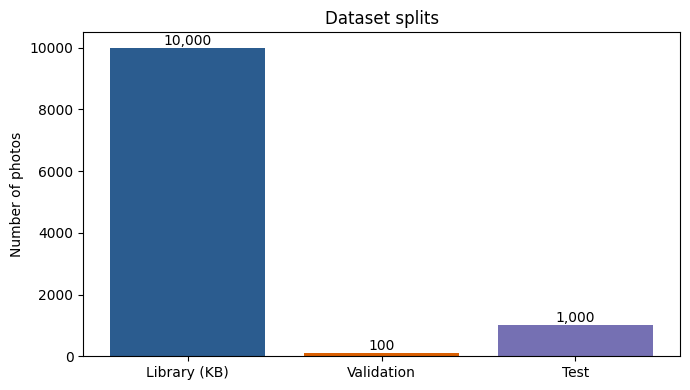

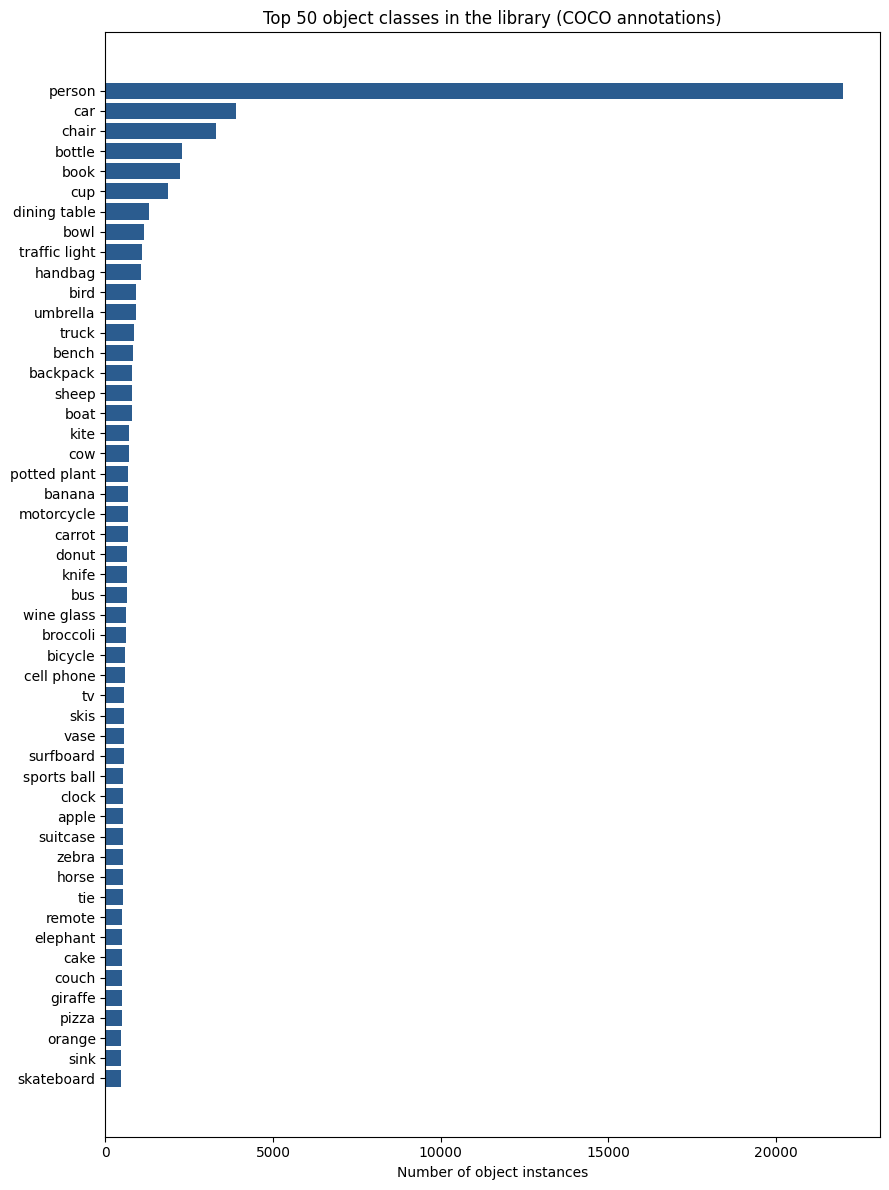

photos containing a person: 54.0%


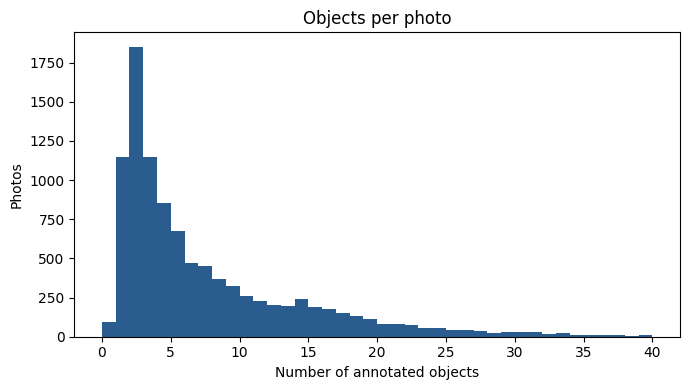

mean 7.27 | median 4 | max 93


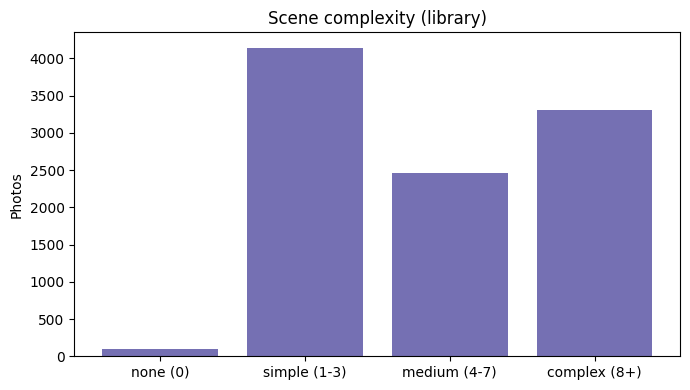

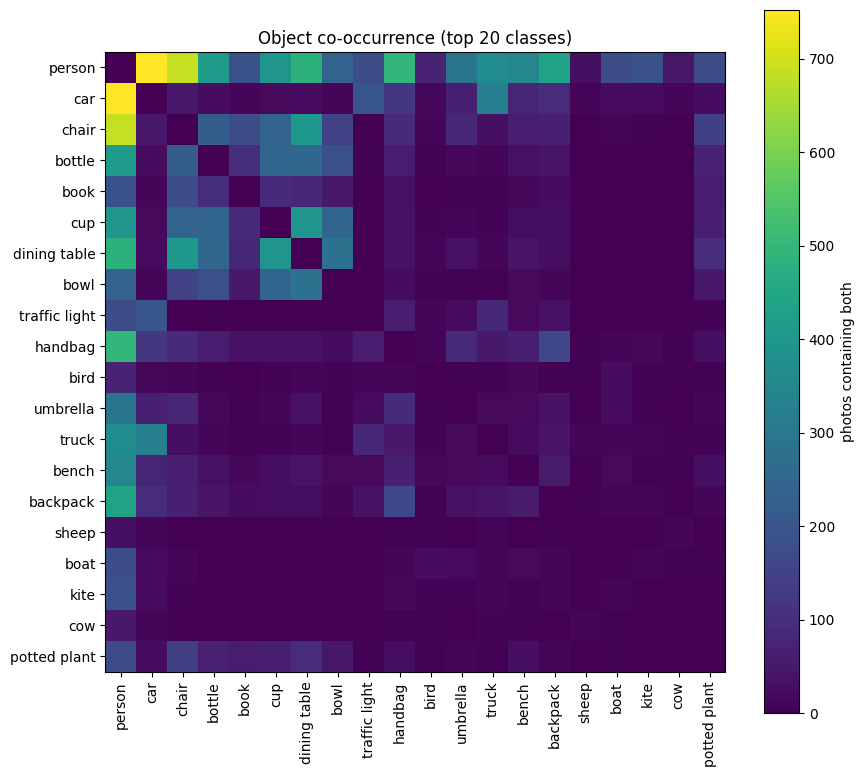

In [10]:
# ===== B3b: Object and scene charts =====
# 1. Splits
fig, ax = plt.subplots(figsize=(7, 4))
vals = [len(kb), len(val), len(test)]
bars = ax.bar(["Library (KB)", "Validation", "Test"], vals, color=["#2b5c8f", "#d95f02", "#7570b3"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Dataset splits"); ax.set_ylabel("Number of photos")
plt.tight_layout(); plt.savefig(FIG / "01_splits.png", dpi=200); plt.show()

# 2. Top 50 object classes (instances)
cls_count = collections.Counter(c for i in kb for c in objs[i])
top = cls_count.most_common(50)
plt.figure(figsize=(9, 12))
plt.barh([cat_name[c] for c, _ in top][::-1], [n for _, n in top][::-1], color="#2b5c8f")
plt.title("Top 50 object classes in the library (COCO annotations)"); plt.xlabel("Number of object instances")
plt.tight_layout(); plt.savefig(FIG / "02_top50_classes.png", dpi=200); plt.show()
person_share = sum(1 for i in kb if 1 in objs[i]) / len(kb)
print(f"photos containing a person: {person_share:.1%}")

# 3. Objects per photo
n_obj = [len(objs[i]) for i in kb]
plt.figure(figsize=(7, 4)); plt.hist(n_obj, bins=range(0, 41), color="#2b5c8f")
plt.title("Objects per photo"); plt.xlabel("Number of annotated objects"); plt.ylabel("Photos")
plt.tight_layout(); plt.savefig(FIG / "03_objects_per_photo.png", dpi=200); plt.show()
print(f"mean {np.mean(n_obj):.2f} | median {np.median(n_obj):.0f} | max {max(n_obj)}")

# 4. Scene complexity
def bucket(n):
    return "none (0)" if n == 0 else "simple (1-3)" if n <= 3 else "medium (4-7)" if n <= 7 else "complex (8+)"
order = ["none (0)", "simple (1-3)", "medium (4-7)", "complex (8+)"]
cx = collections.Counter(bucket(n) for n in n_obj)
plt.figure(figsize=(7, 4)); plt.bar(order, [cx[o] for o in order], color="#7570b3")
plt.title("Scene complexity (library)"); plt.ylabel("Photos")
plt.tight_layout(); plt.savefig(FIG / "04_scene_complexity.png", dpi=200); plt.show()

# 5. Co-occurrence of the 20 most frequent classes
top20 = [c for c, _ in cls_count.most_common(20)]
idx = {c: k for k, c in enumerate(top20)}
M = np.zeros((20, 20), dtype=int)
for i in kb:
    for a, b in itertools.combinations(sorted(set(objs[i]) & set(top20)), 2):
        M[idx[a], idx[b]] += 1; M[idx[b], idx[a]] += 1
plt.figure(figsize=(9, 8)); plt.imshow(M, cmap="viridis"); plt.colorbar(label="photos containing both")
labels = [cat_name[c] for c in top20]
plt.xticks(range(20), labels, rotation=90); plt.yticks(range(20), labels)
plt.title("Object co-occurrence (top 20 classes)")
plt.tight_layout(); plt.savefig(FIG / "05_cooccurrence.png", dpi=200); plt.show()

stats["objects"] = {"classes_present": len(cls_count), "mean_per_photo": float(np.mean(n_obj)),
                    "median_per_photo": float(np.median(n_obj)), "person_share": person_share,
                    "complexity": {o: cx[o] for o in order}}

### B3c. Charts: caption length, vocabulary, word types

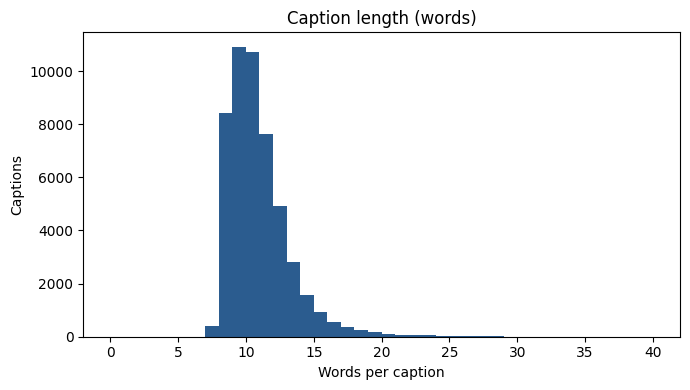

captions 50031 | mean 10.45 | std 2.40 | vocabulary 9864


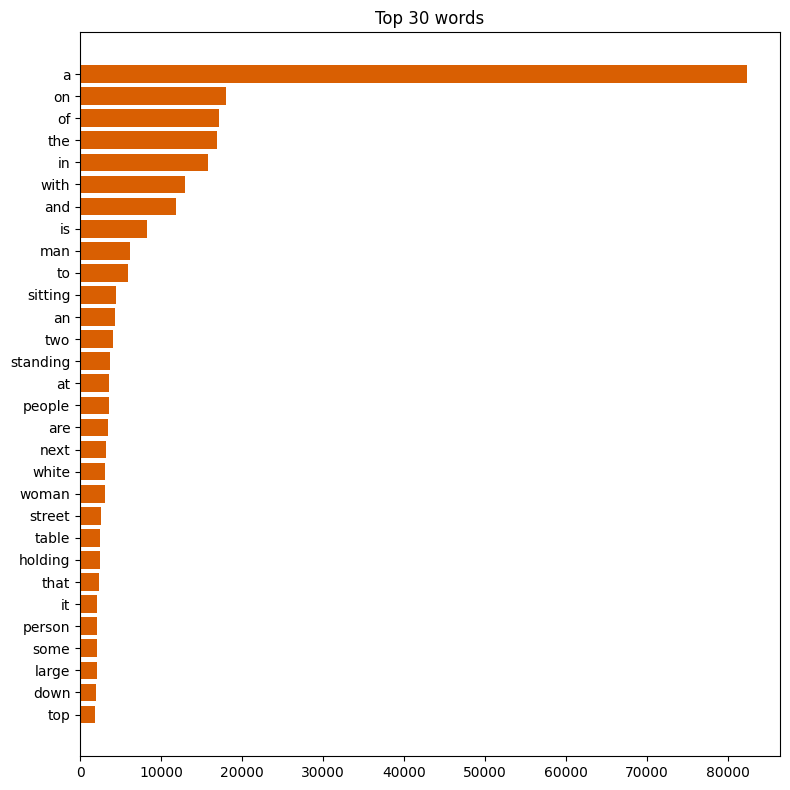

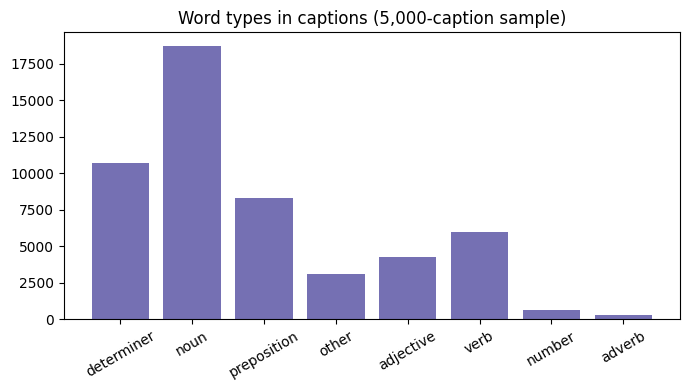

In [11]:
# ===== B3c: Caption charts =====
import nltk
texts = [c for i in kb for c in caps[i]]
lens = [len(t.split()) for t in texts]
words = collections.Counter(w for t in texts for w in re.findall(r"[a-z']+", t.lower()))

plt.figure(figsize=(7, 4)); plt.hist(lens, bins=range(0, 41), color="#2b5c8f")
plt.title("Caption length (words)"); plt.xlabel("Words per caption"); plt.ylabel("Captions")
plt.tight_layout(); plt.savefig(FIG / "06_caption_length.png", dpi=200); plt.show()
print(f"captions {len(texts)} | mean {np.mean(lens):.2f} | std {np.std(lens):.2f} | vocabulary {len(words)}")

top_w = words.most_common(30)
plt.figure(figsize=(8, 8))
plt.barh([w for w, _ in top_w][::-1], [n for _, n in top_w][::-1], color="#d95f02")
plt.title("Top 30 words"); plt.tight_layout(); plt.savefig(FIG / "07_top_words.png", dpi=200); plt.show()

# Word types (part of speech) on a sample of 5,000 captions
for res in ("averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"):
    nltk.download(res, quiet=True)
def group(tag):
    for p, g in (("NN", "noun"), ("VB", "verb"), ("JJ", "adjective"), ("RB", "adverb"),
                 ("IN", "preposition"), ("DT", "determiner"), ("CD", "number")):
        if tag.startswith(p):
            return g
    return "other"
sample = random.Random(SEED).sample(texts, min(5000, len(texts)))
pos = collections.Counter(group(t) for s in sample for _, t in nltk.pos_tag(s.lower().split()))
plt.figure(figsize=(7, 4)); plt.bar(list(pos.keys()), list(pos.values()), color="#7570b3")
plt.title("Word types in captions (5,000-caption sample)"); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(FIG / "08_word_types.png", dpi=200); plt.show()

stats["captions"] = {"total": len(texts), "mean_length": float(np.mean(lens)), "std_length": float(np.std(lens)),
                     "median_length": float(np.median(lens)), "vocabulary_size": len(words), "pos_sample": dict(pos)}

### B3d. Charts: colours and contexts (keyword counts), then save the statistics

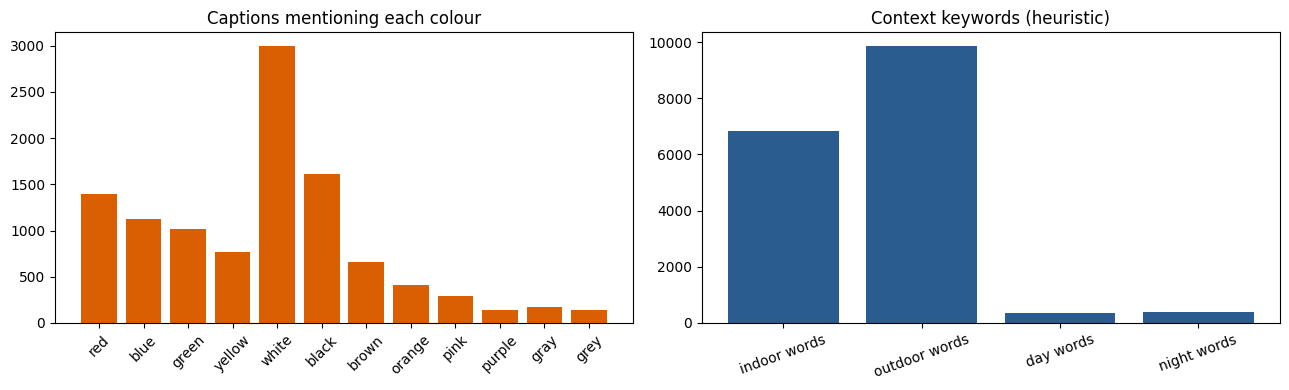

✅ charts saved in reports/figures, numbers saved in reports/phase1_statistics.json


In [12]:
# ===== B3d: Diversity =====
colour_words = ["red", "blue", "green", "yellow", "white", "black", "brown", "orange", "pink", "purple", "gray", "grey"]
indoor_words = ["kitchen", "bathroom", "bedroom", "indoor", "inside", "office", "restaurant", "room", "table"]
outdoor_words = ["outdoor", "outside", "street", "beach", "field", "park", "road", "mountain", "snow", "sky", "grass", "city"]
day_words = ["day", "sunny", "daytime", "morning", "afternoon"]
night_words = ["night", "dark", "evening", "sunset"]

tok = [set(re.findall(r"[a-z']+", t.lower())) for t in texts]
def count_in(wordlist):
    return {w: sum(1 for s in tok if w in s) for w in wordlist}
colours = count_in(colour_words)
groups = {"indoor words": sum(any(w in s for w in indoor_words) for s in tok),
          "outdoor words": sum(any(w in s for w in outdoor_words) for s in tok),
          "day words": sum(any(w in s for w in day_words) for s in tok),
          "night words": sum(any(w in s for w in night_words) for s in tok)}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.bar(list(colours.keys()), list(colours.values()), color="#d95f02")
a1.set_title("Captions mentioning each colour"); a1.tick_params(axis="x", rotation=45)
a2.bar(list(groups.keys()), list(groups.values()), color="#2b5c8f")
a2.set_title("Context keywords (heuristic)"); a2.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG / "09_diversity.png", dpi=200); plt.show()

stats["diversity"] = {"colours": colours, "contexts": groups,
                      "note": "keyword heuristic, not a scene classifier"}
json.dump(stats, open("reports/phase1_statistics.json", "w"), indent=2)
print("✅ charts saved in reports/figures, numbers saved in reports/phase1_statistics.json")

### B3e. Spatial relationships between objects (bounding-box heuristic)

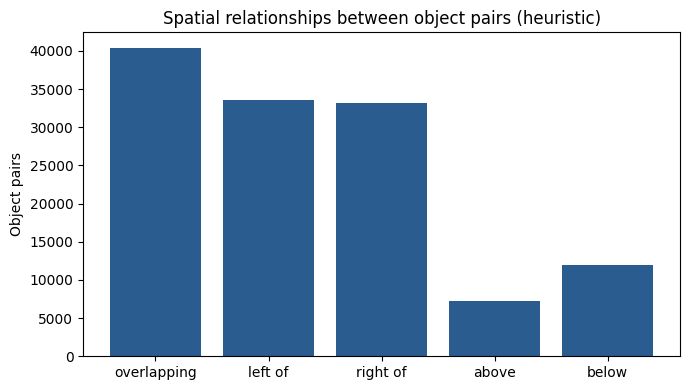

{'overlapping': 40411, 'left of': 33562, 'right of': 33144, 'above': 7259, 'below': 11892, 'note': 'bounding-box heuristic on the 8 largest objects per photo'}


In [13]:
# ===== B3e: Spatial relationships =====
def relation(a, b):
    # relation of box a relative to box b; each box is (x, y, w, h)
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx))
    iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    if ix * iy > 0:
        return "overlapping"
    dx = (ax + aw / 2) - (bx + bw / 2)
    dy = (ay + ah / 2) - (by + bh / 2)
    if abs(dx) >= abs(dy):
        return "left of" if dx < 0 else "right of"
    return "above" if dy < 0 else "below"

rel_count = collections.Counter()
for i in kb:
    biggest = sorted(boxes[i], key=lambda b: b[3] * b[4], reverse=True)[:8]   # 8 largest objects per photo
    for p, q in itertools.combinations(biggest, 2):
        rel_count[relation(p[1:], q[1:])] += 1

order = ["overlapping", "left of", "right of", "above", "below"]
plt.figure(figsize=(7, 4)); plt.bar(order, [rel_count[o] for o in order], color="#2b5c8f")
plt.title("Spatial relationships between object pairs (heuristic)"); plt.ylabel("Object pairs")
plt.tight_layout(); plt.savefig(FIG / "10_spatial_relationships.png", dpi=200); plt.show()

stats["spatial"] = {o: rel_count[o] for o in order}
stats["spatial"]["note"] = "bounding-box heuristic on the 8 largest objects per photo"
json.dump(stats, open("reports/phase1_statistics.json", "w"), indent=2)
print(stats["spatial"])

### B4 (optional). A stratified list of 100 test photos
Use this only if the professor wants **100** test photos. It picks 100 (30 simple, 40 medium, 30 complex scenes) **from the 1,000 test photos you already have**, so no new download is needed. It **does not change** `test_ids.json`: it writes a separate file, `test_ids_100.json`.

In [14]:
# ===== B4 (optional): stratified 100 test photos =====
import json, collections, random, os
assert os.path.exists(f"{ANN}/instances_val2017.json"), "Annotations missing: run B0 with the full zip."

test_all = json.load(open("data/splits/test_ids.json")); ts = set(test_all)
cap_n = collections.Counter(a["image_id"] for a in json.load(open(f"{ANN}/captions_val2017.json"))["annotations"])
n_obj = collections.Counter(a["image_id"] for a in json.load(open(f"{ANN}/instances_val2017.json"))["annotations"]
                            if a["image_id"] in ts)
bins = {"simple": [], "medium": [], "complex": []}
for i in sorted(test_all):
    if cap_n[i] < 5 or n_obj[i] == 0:
        continue
    bins["simple" if n_obj[i] <= 3 else "medium" if n_obj[i] <= 7 else "complex"].append(i)

quota = {"simple": 30, "medium": 40, "complex": 30}
chosen = []
for b, q in quota.items():
    random.Random(SEED).shuffle(bins[b])
    if len(bins[b]) < q:
        print(f"⚠️ only {len(bins[b])} {b} photos available (wanted {q})")
    chosen += bins[b][:q]
chosen = sorted(chosen)
assert set(chosen) <= ts, "chosen photos must come from the frozen test set"
json.dump(chosen, open("data/splits/test_ids_100.json", "w"), indent=2)
print(f"✅ {len(chosen)} photos saved to data/splits/test_ids_100.json | available per bin:", {b: len(v) for b, v in bins.items()})

✅ 100 photos saved to data/splits/test_ids_100.json | available per bin: {'simple': 400, 'medium': 240, 'complex': 353}


---
# Part C: Package and prepare the GitHub files
**Prerequisite:** the audit (A4) passed. Nothing is overwritten: the new zip has a different name.
### C1. Light zip for teammates (no photos, no COCO annotations)

In [15]:
# ===== C1: Light zip =====
import zipfile, os
from pathlib import Path
assert "errors" in globals() and not errors, "Run the audit (A4) and make it pass first."

out = Path("/content/drive/MyDrive/RAG_Project_Phase1_Light.zip")
folders = ["data/splits", "data/processed", "data/embeddings", "data/index", "reports"]
n_files = 0
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for f in folders:
        for p in Path(f).rglob("*"):
            if p.is_file():
                z.write(p, p.as_posix()); n_files += 1
print(f"✅ {out.name}: {n_files} files, {out.stat().st_size / 1e6:.0f} MB")
print("Teammates: put it in My Drive, set ZIP_NAME = 'RAG_Project_Phase1_Light.zip', run Part A.")

✅ RAG_Project_Phase1_Light.zip: 39 files, 236 MB
Teammates: put it in My Drive, set ZIP_NAME = 'RAG_Project_Phase1_Light.zip', run Part A.


### C2. README, requirements.txt, .gitignore and the small result files, copied to Drive

In [16]:
# ===== C2: GitHub files =====
import json, shutil, os
from pathlib import Path
Path("repo_files").mkdir(exist_ok=True)

requirements = ["numpy", "pillow", "torch", "transformers", "faiss-cpu==1.15.1", "ultralytics==8.4.197",
                "matplotlib", "seaborn", "tqdm", "imagehash", "nltk"]
open("repo_files/requirements.txt", "w").write("\n".join(requirements) + "\n")

gitignore = ["# big files live on Google Drive", "data/*", "!data/splits/", "!data/splits/*.json",
             "*.npy", "*.index", "*.faiss", "*.zip", "*.pt", "",
             ".ipynb_checkpoints/", "__pycache__/", ".env"]
open("repo_files/.gitignore", "w").write("\n".join(gitignore) + "\n")

yset = json.load(open("data/processed/yolo_settings.json")) if os.path.exists("data/processed/yolo_settings.json") else {}
clean = json.load(open("data/splits/cleaning_report.json")) if os.path.exists("data/splits/cleaning_report.json") else {}
n_kb = len(json.load(open("data/splits/kb_ids.json")))
n_val = len(json.load(open("data/splits/val_ids.json")))
n_test = len(json.load(open("data/splits/test_ids.json")))

readme = [
 "# G30: Metadata-Filtered RAG for Image Captioning (Phase 1)", "",
 "Mini project, image processing. Group G30. Technique: **Metadata-Filtered RAG**.", "",
 "## Team", "(add names and roles here)", "",
 "## What Phase 1 contains",
 f"- Frozen splits: library (knowledge base) {n_kb} photos from COCO train2017, validation {n_val} photos "
 f"(train2017, outside the library), test {n_test} photos from COCO val2017.",
 "- Anti-leakage audit: no photo appears in two splits (checked in the notebook).",
 f"- YOLO object metadata for every photo (model {yset.get('model', 'yolov8n.pt')}, "
 f"confidence threshold {yset.get('conf_threshold', 'see notebook')}).",
 "- CLIP image and caption embeddings (512 dimensions, L2-normalised) and FAISS flat indexes (inner product = cosine).",
 f"- Cleaning report (missing, corrupted, duplicate photos). Library captions in total: {clean.get('kb_total_captions', 'n/a')}.",
 "- Exploration charts and statistics in `reports/`.", "",
 "## Repository contents",
 "- `Metadata_RAG_Phase1_Final.ipynb`: the notebook (Part A restore and verify, Part B cleaning and exploration, Part C packaging)",
 "- `data/splits/`: frozen ID files and the cleaning report (never edit)",
 "- `reports/`: figures and `phase1_statistics.json`",
 "- `requirements.txt`, `.gitignore`", "",
 "## Big files (not on GitHub)",
 "Embeddings (`.npy`), FAISS indexes and photos are too large for GitHub. They are in the zip "
 "`RAG_Project_Phase1_Light.zip` on the team Google Drive.", "",
 "## How to run (Google Colab)",
 "1. Put `RAG_Project_Phase1_Light.zip` in your My Drive (right-click the shared file, Make a copy).",
 "2. Open the notebook in Colab, switch the runtime to T4 GPU.",
 "3. In the CONFIG cell set `ZIP_NAME = \"RAG_Project_Phase1_Light.zip\"`.",
 "4. Run cells A1 to A4. The last line must say `ALL CHECKS PASSED`.", "",
 "## Reproducibility",
 "Random seed 42. The split ID files are the source of truth: load them, never regenerate them.", "",
 "## Known limitations",
 "- The test set was drawn at random from val2017 (not stratified); the size is to be confirmed with the instructor.",
 "- Spatial relationships are a simple bounding-box heuristic (overlapping, left of, right of, above, below).",
 "- Embedding generation code is kept in `src/` (to be added).",
]
if os.path.exists("data/splits/test_ids_100.json"):
    readme.append("- `data/splits/test_ids_100.json` is an optional stratified 100-photo subset of the test set, "
                  "prepared in case 100 test photos are required.")
open("repo_files/README.md", "w").write("\n".join(readme) + "\n")

dst = Path(DRIVE_OUT); dst.mkdir(parents=True, exist_ok=True)
for f in ["data/splits/kb_ids.json", "data/splits/val_ids.json", "data/splits/test_ids.json",
          "data/splits/cleaning_report.json", "data/processed/yolo_metadata.json",
          "data/processed/yolo_metadata_test.json", "data/processed/yolo_settings.json",
          "reports/phase1_statistics.json"]:
    if os.path.exists(f):
        shutil.copy(f, dst / Path(f).name)
for f in Path("repo_files").glob("*"):
    shutil.copy(f, dst / f.name)
if Path("reports/figures").exists():
    shutil.copytree("reports/figures", dst / "figures", dirs_exist_ok=True)
print("✅ Copied to Drive:", DRIVE_OUT)
print(sorted(p.name for p in dst.iterdir()))

✅ Copied to Drive: /content/drive/MyDrive/g30_project/phase1_outputs
['.gitignore', 'README.md', 'cleaning_report.json', 'figures', 'kb_ids.json', 'phase1_statistics.json', 'requirements.txt', 'test_ids.json', 'val_ids.json', 'yolo_metadata.json', 'yolo_metadata_test.json', 'yolo_settings.json']


### Final step: GitHub
Download the folder `g30_project/phase1_outputs` from Drive, then upload to the repo through the website (**Add file → Upload files**): `README.md`, `requirements.txt`, `.gitignore`, the three split ID files, `cleaning_report.json`, the `figures` folder, and this notebook (**File → Download → .ipynb**). Do not upload anything from `data/` except the small JSON files above, and never use `git push --force`.